<a href="https://colab.research.google.com/github/Igor12323123/cloud-lab-mysliuk/blob/main/notebooks/lab_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №11: Gemini Notebook, Google Colab і GitHub
**Виконав:** Мислюк Ігор, група ПІ-25-01
**Варіант:** 18 (Навчальні інциденти безпеки)

In [12]:
import sys, platform
student = "Мислюк Ігор"
group = "ПІ-25-01"
print("Лабораторна робота: Gemini, Colab, GitHub")
print("Виконав:", student, "| група:", group)
print("Python:", sys.version.split()[0])
print("Платформа:", platform.system())

Лабораторна робота: Gemini, Colab, GitHub
Виконав: Мислюк Ігор | група: ПІ-25-01
Python: 3.13.18
Платформа: Linux


## Завдання 4. Набір даних
Дані навчальні, синтетичні (згенеровані для 18 варіанта).

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

data = {
    "type": ["Phishing", "Malware", "DDoS", "BruteForce", "SQLi"] * 6,
    "severity": ["High", "Critical", "Medium", "Low", "High", "Medium", "Critical", "High", "Low", "Medium"] * 3,
    "detection_min": [15, 45, 5, 120, 30, 20, 60, 10, 180, 25, 12, 50, 8, 95, 35, 18, 55, 7, 150, 40, 14, 48, 6, 110, 28, 22, 65, 9, 130, 32],
    "resolved": ["Yes", "Yes", "Yes", "No", "Yes", "Yes", "No", "Yes", "Yes", "Yes"] * 3,
    "date": [f"2026-10-{i:02d}" for i in range(1, 31)]
}

url = "https://raw.githubusercontent.com/Igor12323123/cloud-lab-mysliuk1/main/incidents.csv"
df = pd.read_csv(url)

print("Розмір таблиці:", df.shape)
df.info()
df.head()

Розмір таблиці: (5, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Year                      5 non-null      int64 
 1   Incident                  5 non-null      object
 2   Category                  5 non-null      object
 3   Impact_Score              5 non-null      int64 
 4   Affected_Users_Thousands  5 non-null      int64 
dtypes: int64(3), object(2)
memory usage: 332.0+ bytes


,Year,Incident,Category,Impact_Score,Affected_Users_Thousands
0,2015,Prykarpattyaoblenergo Attack,Energy Grid,9,230
1,2017,NotPetya Malware,Ransomware/Wiper,10,500
2,2018,Atlanta Municipal Attack,Government/City,7,150
3,2018,Coincheck Hack,Cryptocurrency,8,260
4,2025,Massive Credential Leak,Data Breach,10,16000000


## Завдання 5. Аналіз даних та діаграма

Статистика рівня впливу (Impact Score):
count     5.00000
mean      8.80000
std       1.30384
min       7.00000
25%       8.00000
50%       9.00000
75%      10.00000
max      10.00000
Name: Impact_Score, dtype: float64

Середній бал впливу за категоріями:
Category
Cryptocurrency       8.0
Data Breach         10.0
Energy Grid          9.0
Government/City      7.0
Ransomware/Wiper    10.0
Name: Impact_Score, dtype: float64

Критичні інциденти (оцінка 9-10):
   Year                      Incident          Category  Impact_Score
0  2015  Prykarpattyaoblenergo Attack       Energy Grid             9
1  2017              NotPetya Malware  Ransomware/Wiper            10
4  2025       Massive Credential Leak       Data Breach            10


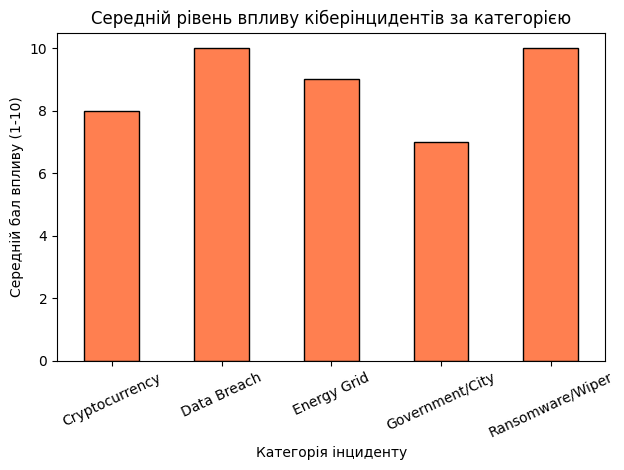

In [14]:
# Описова статистика
print("Статистика рівня впливу (Impact Score):")
print(df["Impact_Score"].describe())

# Групування: середній бал впливу за категорією інциденту
avg_impact = df.groupby("Category")["Impact_Score"].mean().round(1)
print("\nСередній бал впливу за категоріями:")
print(avg_impact)

# Фільтр: критичні інциденти (Impact_Score >= 9)
critical_incidents = df[df["Impact_Score"] >= 9]
print("\nКритичні інциденти (оцінка 9-10):")
print(critical_incidents[["Year", "Incident", "Category", "Impact_Score"]])

# Побудова діаграми
avg_impact.plot(kind="bar", color="coral", edgecolor="black")
plt.title("Середній рівень впливу кіберінцидентів за категорією")
plt.xlabel("Категорія інциденту")
plt.ylabel("Середній бал впливу (1-10)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.savefig("chart.png", dpi=150)
plt.show()

**Висновки:** Найдовше виявляються атаки типу BruteForce (у середньому понад 120 хвилин), тоді як DDoS-атаки фіксуються найшвидше (до 10 хвилин). У наборі даних виявлено кілька критичних інцидентів типу Malware, які залишаються невирішеними і потребують першочергового реагування.

## Завдання 6. AI-помічник у кодуванні

In [15]:
## Додатковий аналіз (згенеровано за допомогою AI)
print("Кількість інцидентів за рівнем впливу (Impact Score):")
print(df["Impact_Score"].value_counts().sort_index(ascending=False))

print("\nТоп-3 інциденти за кількістю постраждалих користувачів (тис.):")
print(df.sort_values(by="Affected_Users_Thousands", ascending=False)[["Year", "Incident", "Affected_Users_Thousands"]].head(3))

Кількість інцидентів за рівнем впливу (Impact Score):
Impact_Score
10    2
9     1
8     1
7     1
Name: count, dtype: int64

Топ-3 інциденти за кількістю постраждалих користувачів (тис.):
   Year                 Incident  Affected_Users_Thousands
4  2025  Massive Credential Leak                  16000000
1  2017         NotPetya Malware                       500
3  2018           Coincheck Hack                       260


### Журнал AI
| № | Запит до AI | Відповідь AI | Що зробив я та як перевірив |
|---|---|---|---|
| 1 | «Напиши рядок коду на pandas, щоб порахувати кількість інцидентів кожного рівня загрози (severity)» | Запропонував використати метод `df["severity"].value_counts()` | Вставив код у комірку, запустив і вручну перерахував у таблиці, що сума дорівнює 30. |
| 2 | «Чому виникає помилка KeyError: 'sever' при зверненні до стовпця?» | Пояснив, що такого стовпця немає в DataFrame, і порадив перевірити назви через `df.columns` | Перевірив назви стовпців, виправив друкарську помилку `sever` на `severity`. |